In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker

In [3]:
# Define file paths
abonly_file_path = "merged.dna.txt"
gof_mutations_file_path = "known_GOFmut_1BF5"

# Define correct column headers for abonly data
correct_headers_abonly = [
    "Pdb", "Group1", "Group2", "IntraclashesGroup1", "IntraclashesGroup2",
    "Interaction Energy", "StabilityGroup1", "StabilityGroup2"
]

# Load the abonly data while skipping redundant headers
data_abonly = pd.read_csv(abonly_file_path, sep="\t", header=0, names=correct_headers_abonly, comment='P')

# Drop potential NaN rows and reset index
data_abonly = data_abonly.dropna().reset_index(drop=True)

# Extract MutationIndex from Pdb filenames (e.g., ./1BF5_Dimer_Repair_10_1.pdb → 10)
data_abonly["MutationIndex"] = data_abonly["Pdb"].str.extract(r'_(\d+)_\d+\.pdb')[0].astype(float)

# Convert "Interaction Energy" to numeric
data_abonly["Interaction Energy"] = pd.to_numeric(data_abonly["Interaction Energy"], errors='coerce')

# Load known GOF mutations data without headers
updated_gof_mutations = pd.read_csv(gof_mutations_file_path, sep="\t", header=None)

# Assign column names manually
updated_gof_mutations.columns = ["MutationIndex", "Mutation", "Domain"]

# Extract ResidueIndex from Mutation names (e.g., "T419R" -> 419)
updated_gof_mutations["ResidueIndex"] = updated_gof_mutations["Mutation"].str.extract(r'(\d+)')[0].astype(float)

# Merge extracted MutationIndex with ResidueIndex from known mutations
data_annotated_abonly = data_abonly.merge(updated_gof_mutations[["MutationIndex", "ResidueIndex", "Mutation", "Domain"]], on="MutationIndex", how="left")

# Sort data by ResidueIndex for correct scaling
data_annotated_abonly = data_annotated_abonly.sort_values(by="ResidueIndex")

# Define residue index ranges for domains
domain_ranges = {
    #"ND": (1, 133),
    "CCD": (134, 316),
    "DBD": (317, 487),
    "LD": (488, 575),
    "SH2": (576, 682),
    "TAD": (683, 750)
}

# Define colors for domains
domain_colors = {
    #"ND": "pink",
    "CCD": "blue",
    "DBD": "red",
    "LD": "green",
    "SH2": "yellow",
    "TAD": "purple"
}

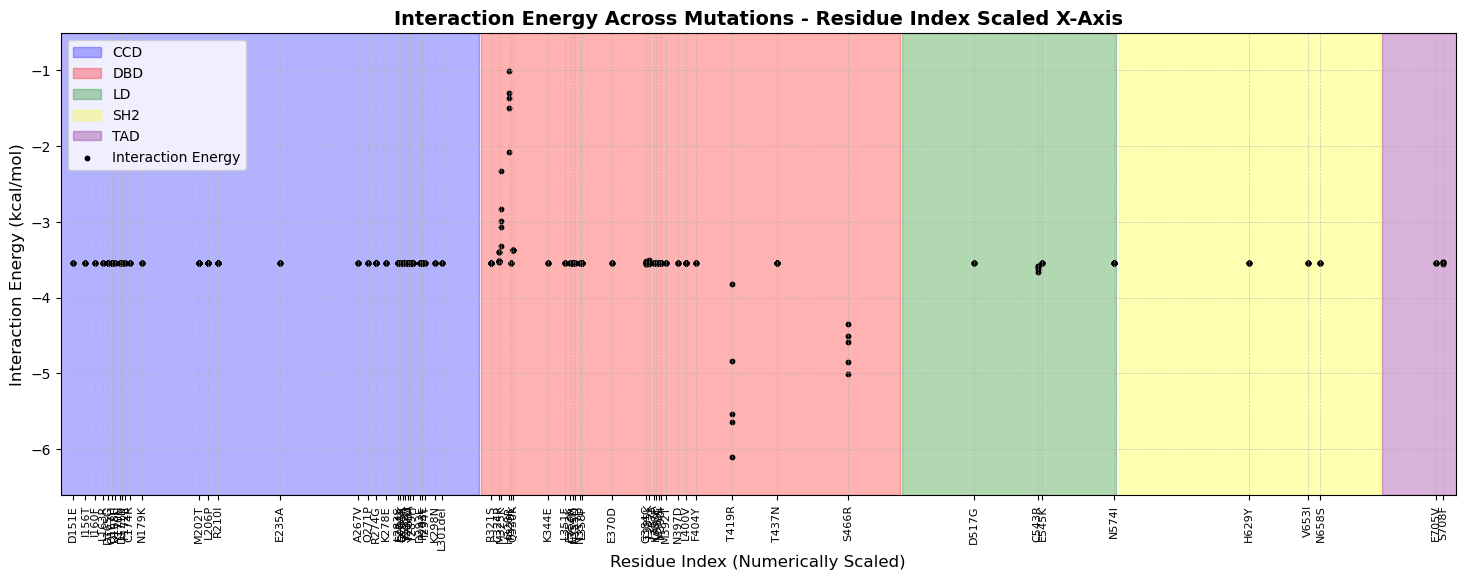

In [4]:
# Create the properly scaled plot
fig, ax = plt.subplots(figsize=(18, 6))

# Set y-axis limits with padding
y_min = data_annotated_abonly["Interaction Energy"].min() - 0.5
y_max = data_annotated_abonly["Interaction Energy"].max() + 0.5
ax.set_ylim(y_min, y_max)

# Set x-axis limits using true numerical scale of ResidueIndex
x_min = data_annotated_abonly["ResidueIndex"].min() - 5
x_max = data_annotated_abonly["ResidueIndex"].max() + 5
ax.set_xlim(x_min, x_max)

# Add background colors based on domain ranges
for domain, (start, end) in domain_ranges.items():
    ax.add_patch(patches.Rectangle(
        (start, y_min),  # Start x position and y lower bound
        end - start,  # Width
        y_max - y_min,  # Height
        color=domain_colors[domain], alpha=0.3, label=domain if domain not in ax.get_legend_handles_labels()[1] else ""
    ))

# Plot interaction energy data points **with proper ResidueIndex scaling**
ax.scatter(data_annotated_abonly["ResidueIndex"], data_annotated_abonly["Interaction Energy"], color="black", label="Interaction Energy", s=10)

# Ensure **all ResidueIndex labels align correctly**
unique_residues = data_annotated_abonly.drop_duplicates(subset=["ResidueIndex"])
ax.set_xticks(unique_residues["ResidueIndex"])
ax.set_xticklabels(unique_residues["Mutation"], rotation=90, fontsize=8)

# Label axes
ax.set_xlabel("Residue Index (Numerically Scaled)", fontsize=12)
ax.set_ylabel("Interaction Energy (kcal/mol)", fontsize=12)
ax.set_title("Interaction Energy Across Mutations - Residue Index Scaled X-Axis", fontsize=14, fontweight='bold')
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)  # Light grid for clarity

# Add legend
ax.legend()

# Show the plot
plt.show()

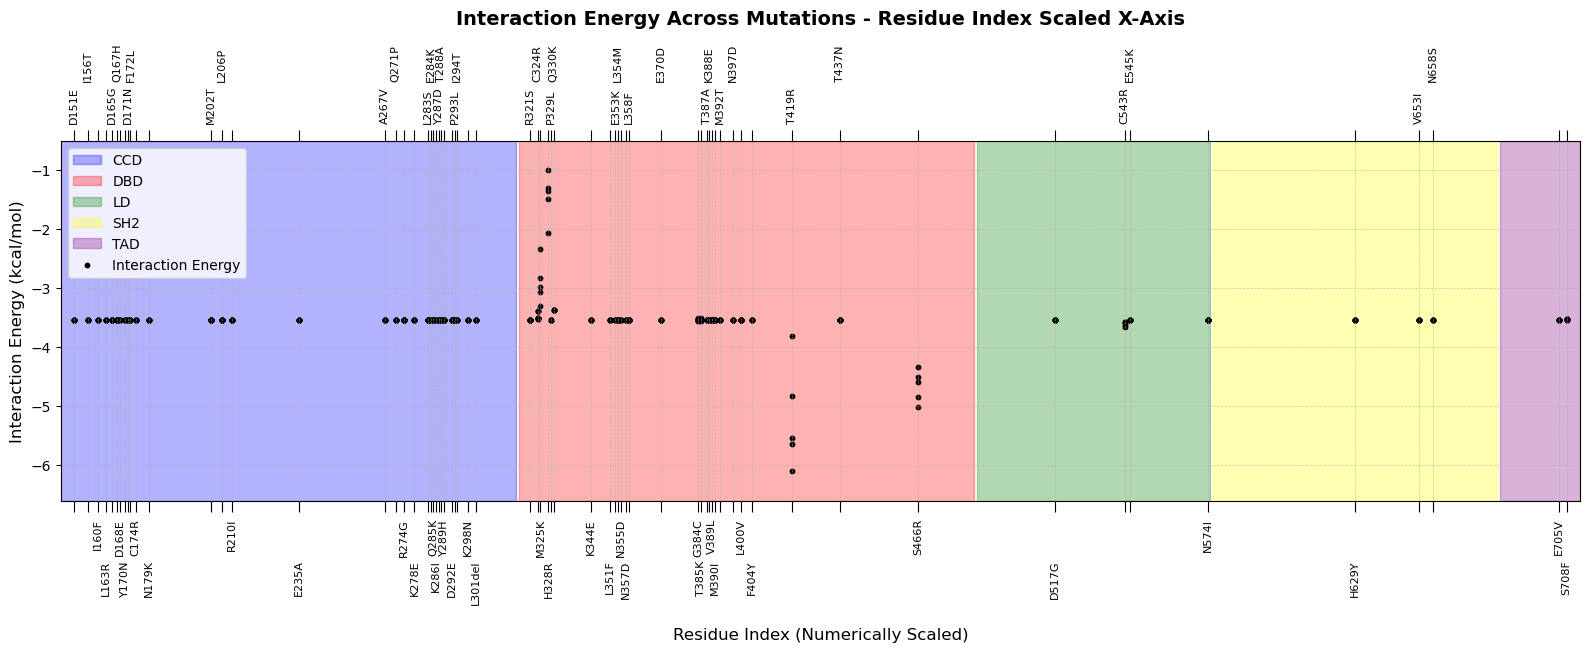

In [5]:
# Create the properly scaled plot
fig, ax = plt.subplots(figsize=(16, 6))

# Set y-axis limits with padding
y_min = data_annotated_abonly["Interaction Energy"].min() - 0.5
y_max = data_annotated_abonly["Interaction Energy"].max() + 0.5
ax.set_ylim(y_min, y_max)

# Set x-axis limits using true numerical scale of ResidueIndex
x_min = data_annotated_abonly["ResidueIndex"].min() - 5
x_max = data_annotated_abonly["ResidueIndex"].max() + 5
ax.set_xlim(x_min, x_max)

# Add background colors based on domain ranges
for domain, (start, end) in domain_ranges.items():
    ax.add_patch(patches.Rectangle(
        (start, y_min),  # Start x position and y lower bound
        end - start,  # Width
        y_max - y_min,  # Height
        color=domain_colors[domain], alpha=0.3, label=domain if domain not in ax.get_legend_handles_labels()[1] else ""
    ))

# Plot interaction energy data points with proper ResidueIndex scaling
ax.scatter(data_annotated_abonly["ResidueIndex"], data_annotated_abonly["Interaction Energy"], color="black", label="Interaction Energy", s=10)

# Get unique residues for labeling
unique_residues = data_annotated_abonly.drop_duplicates(subset=["ResidueIndex"])

# Set x-ticks for all ResidueIndex values (for grid alignment and visible ticks)
ax.set_xticks(unique_residues["ResidueIndex"])
ax.tick_params(axis='x', which='both', top=True, bottom=True, length=8, width=0.8)  # Ticks on top and bottom, length=8

# Manually place x-axis labels and draw lines from ticks to labels with four vertical heights (two above, two below)
y_offsets = [0.3, 1.0, -0.3, -1.0]  # Two above (positive), two below (negative)
for i, (res_idx, mutation) in enumerate(zip(unique_residues["ResidueIndex"], unique_residues["Mutation"])):
    # Cycle through four y-offsets
    y_offset = y_offsets[i % 4]
    # Determine if label is above or below (positive or negative offset)
    if y_offset > 0:
        y_pos = y_max + y_offset  # Place above the plot
        tick_ybase = y_max  # Line starts at top tick
        va = 'bottom'  # Align label bottom to extend upward
    else:
        y_pos = y_min + y_offset  # Place below the plot
        tick_ybase = y_min  # Line starts at bottom tick
        va = 'top'  # Align label top to extend downward
    # Draw line from tick to label position
    ax.vlines(res_idx, ymin=y_pos, ymax=tick_ybase, color='black', linewidth=0.5, alpha=0.7)
    # Place label at the end of the line
    ax.text(
        res_idx,  # x-coordinate (numerical ResidueIndex)
        y_pos,  # y-coordinate (staggered above or below)
        mutation,  # Label text (e.g., "T419R")
        rotation=90, fontsize=8, ha='center', va=va
    )

# Disable default x-axis labels to avoid overlap
ax.set_xticklabels([])

# Label axes
# Label axes with adjusted padding
ax.set_xlabel("Residue Index (Numerically Scaled)", fontsize=12, labelpad=80)  # Increased padding
ax.set_ylabel("Interaction Energy (kcal/mol)", fontsize=12)
ax.set_title("Interaction Energy Across Mutations - Residue Index Scaled X-Axis", fontsize=14, fontweight='bold', y=1.3)  # Raise the title further
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)  # Light grid for clarity

# Add legend
ax.legend()

# Adjust layout to prevent label clipping
plt.tight_layout()

# Increase top and bottom margins to accommodate labels and lines
fig.subplots_adjust(top=0.85, bottom=0.25)  # Adjusted for labels above and below

# Save the plot as an image
plt.show()


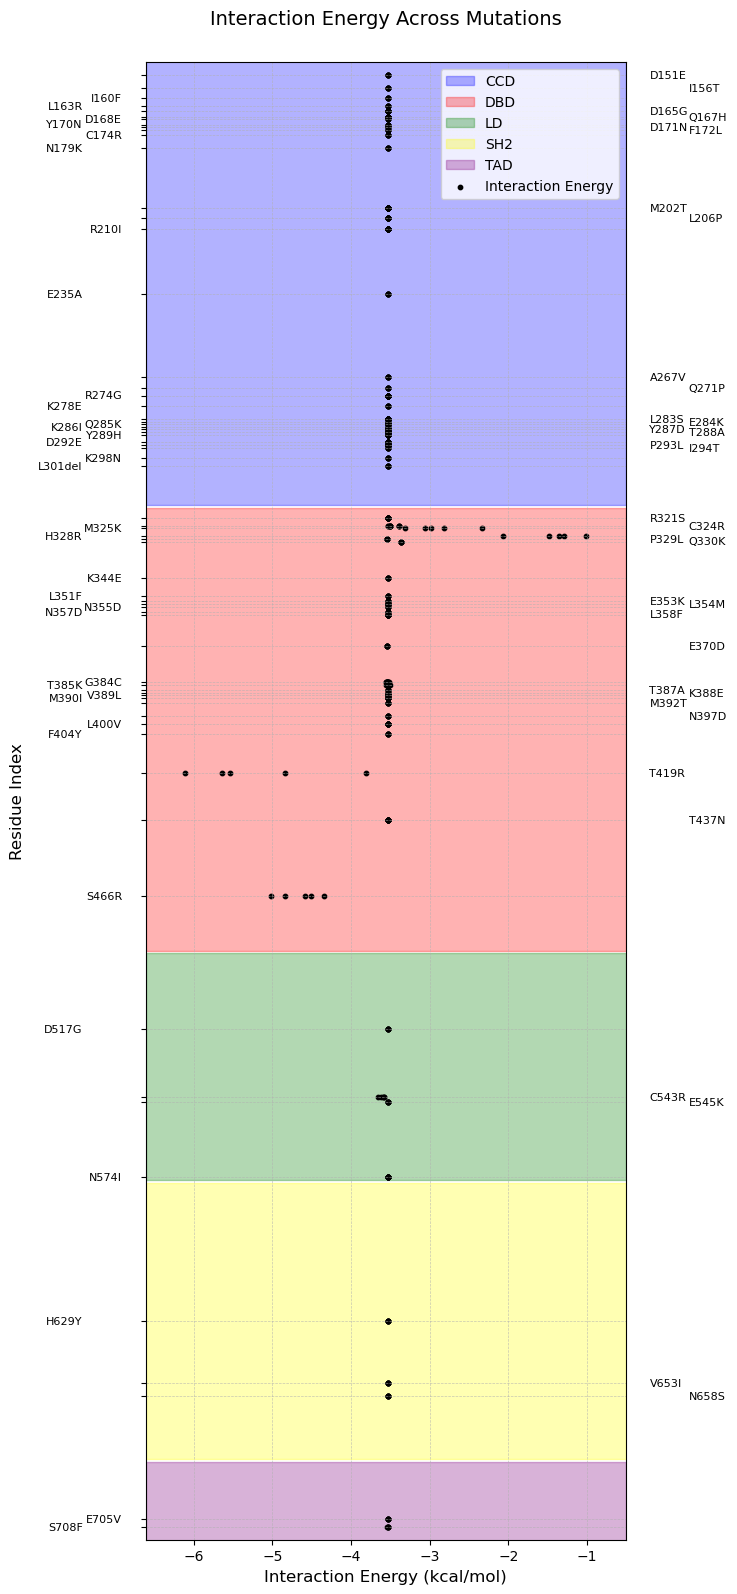

In [ ]:
fig, ax = plt.subplots(figsize=(8, 16))

x_min = data_annotated_abonly["Interaction Energy"].min() - 0.5
x_max = data_annotated_abonly["Interaction Energy"].max() + 0.5
y_min = data_annotated_abonly["ResidueIndex"].min() - 5
y_max = data_annotated_abonly["ResidueIndex"].max() + 5

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_max, y_min)  # Inverted y-axis

# Background domain colors
for domain, (start, end) in domain_ranges.items():
    if domain not in ax.get_legend_handles_labels()[1]:
        ax.add_patch(patches.Rectangle(
            (x_min, start), x_max - x_min, end - start,
            color=domain_colors[domain], alpha=0.3, label=domain
        ))

# Plot interaction energy points
ax.scatter(data_annotated_abonly["Interaction Energy"],
           data_annotated_abonly["ResidueIndex"],
           color="black", s=10, label="Interaction Energy")

unique_residues = data_annotated_abonly.drop_duplicates(subset=["ResidueIndex"])
ax.set_yticks(unique_residues["ResidueIndex"])
ax.set_yticklabels([])  # Remove default labels

# Alternating label placement
x_offsets = [0.3, 0.8, -0.3, -0.8]
for i, (res_idx, mutation) in enumerate(zip(unique_residues["ResidueIndex"], unique_residues["Mutation"])):
    x_offset = x_offsets[i % 4]
    x_pos = (x_max if x_offset > 0 else x_min) + x_offset
    tick_base = x_max if x_offset > 0 else x_min
    ha = 'left' if x_offset > 0 else 'right'

    ax.hlines(res_idx, xmin=tick_base, xmax=x_pos, color='black', linewidth=0.5, alpha=0.7)
    ax.text(x_pos, res_idx, mutation, fontsize=8, ha=ha, va='center')

ax.set_xlabel("Interaction Energy (kcal/mol)", fontsize=12)
ax.set_ylabel("Residue Index", fontsize=12, labelpad=80)
ax.set_title("Interaction Energy Across Mutations", fontsize=14, y=1.02)
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
ax.legend(loc='upper right')

plt.tight_layout()
fig.subplots_adjust(left=0.25, right=0.85)
plt.show()


In [8]:
data_annotated_abonly[data_annotated_abonly["Mutation"]== "T419R"]

,Pdb,Group1,Group2,IntraclashesGroup1,IntraclashesGroup2,Interaction Energy,StabilityGroup1,StabilityGroup2,MutationIndex,ResidueIndex,Mutation,Domain
420,./1BF5_Dimer_Repair_86_1.pdb,CD,AB,39.5275,348.386,-5.54152,17.7863,608.625,86.0,419.0,T419R,DBD
421,./1BF5_Dimer_Repair_86_2.pdb,CD,AB,39.5275,348.192,-5.63575,17.7863,608.870,86.0,419.0,T419R,DBD
422,./1BF5_Dimer_Repair_86_3.pdb,CD,AB,39.5275,348.223,-3.81366,17.7863,608.668,86.0,419.0,T419R,DBD
423,./1BF5_Dimer_Repair_86_4.pdb,CD,AB,39.5362,348.455,-6.10738,17.8115,608.803,86.0,419.0,T419R,DBD
419,./1BF5_Dimer_Repair_86_0.pdb,CD,AB,39.5275,348.202,-4.83640,17.7863,608.604,86.0,419.0,T419R,DBD


In [16]:
data_annotated_abonly[data_annotated_abonly["Mutation"]== "H328R"]

,Pdb,Group1,Group2,IntraclashesGroup1,IntraclashesGroup2,Interaction Energy,StabilityGroup1,StabilityGroup2,MutationIndex,ResidueIndex,Mutation,Domain
265,./1BF5_Dimer_Repair_58_1.pdb,CD,AB,39.5275,349.841,-1.48965,17.7863,610.975,58.0,328.0,H328R,DBD
264,./1BF5_Dimer_Repair_58_0.pdb,CD,AB,39.5275,349.856,-1.35876,17.7863,610.998,58.0,328.0,H328R,DBD
268,./1BF5_Dimer_Repair_58_4.pdb,CD,AB,39.5275,350.379,-2.07110,17.7863,611.244,58.0,328.0,H328R,DBD
267,./1BF5_Dimer_Repair_58_3.pdb,CD,AB,39.5275,349.246,-1.00888,17.7863,610.911,58.0,328.0,H328R,DBD
266,./1BF5_Dimer_Repair_58_2.pdb,CD,AB,39.5275,349.997,-1.29855,17.7863,611.096,58.0,328.0,H328R,DBD


In [19]:
data_annotated_abonly[data_annotated_abonly["Mutation"]== "M325K"]

,Pdb,Group1,Group2,IntraclashesGroup1,IntraclashesGroup2,Interaction Energy,StabilityGroup1,StabilityGroup2,MutationIndex,ResidueIndex,Mutation,Domain
259,./1BF5_Dimer_Repair_57_0.pdb,CD,AB,39.5275,350.061,-2.82269,17.7863,617.565,57.0,325.0,M325K,DBD
260,./1BF5_Dimer_Repair_57_1.pdb,CD,AB,39.5275,349.716,-2.98833,17.7863,618.010,57.0,325.0,M325K,DBD
261,./1BF5_Dimer_Repair_57_2.pdb,CD,AB,39.5275,348.830,-3.06395,17.7863,618.824,57.0,325.0,M325K,DBD
262,./1BF5_Dimer_Repair_57_3.pdb,CD,AB,39.5275,349.676,-2.33332,17.7863,617.176,57.0,325.0,M325K,DBD
263,./1BF5_Dimer_Repair_57_4.pdb,CD,AB,39.5275,350.137,-3.31343,17.7863,618.955,57.0,325.0,M325K,DBD
